# Template Matching für den Chirp-Mass-Proxy (ET-HF-IMBH)

Bank wird einmal erzeugt und gespeichert, die Filterung läuft batchweise auf der GPU. Die Extrinsik wird **nicht** mehr aus der Injektion übernommen (blind). Die Logik steht in `chirp_mass_matcher.py`.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "3"
import numpy as np, matplotlib.pyplot as plt, torch
from dingo.core.posterior_models.build_model import build_model_from_kwargs
from dingo.gw.injection import Injection
import chirp_mass_matcher as cmm
from dingo.gw.noise.asd_dataset import ASDDataset

MODEL_NAME = "stage1"   # anpassen
MODEL_PATH = f"/scratch/tpausch/models/{MODEL_NAME}/model_latest.pt"
BANK_PATH  = f"/scratch/tpausch/test_data/{MODEL_NAME}/chirp_mass_bank.pt"
INJECTION_DIR = f"/scratch/tpausch/test_data/{MODEL_NAME}/injections"

pm = build_model_from_kwargs(filename=MODEL_PATH, device="cpu", load_training_info=False)
pm_metadata = pm.metadata
generator = Injection.from_posterior_model_metadata(pm.metadata)
cfg = cmm.BankConfig.from_metadata(pm.metadata)   # f 6-256, dF 0.125, Mc 75-1200, m1/m2-Constraints
del pm

# ASD fuer den Sanity-Check (signal() liefert keinen ASD); Pfad wie in train_settings stage_0
ASD_PATH = "/scratch/tpausch/ASD/asds_ET_T8.hdf5"
asd_dataset = ASDDataset(file_name=ASD_PATH)
generator.asd = {k: v[0] for k, v in asd_dataset.asds.items()}
print(cfg)

/home/tpausch/ET-Dingo/dingo/gw/__init__.py:3: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal

WARNING!

This object was created using Dingo version 0.1.dev1230+gc9da5d765 < 0.9.0, which broke backwards compatibility.
For models trained prior to this change, new inference results will be unreliable.
Previously-generated result files should be used with caution.
Reasons for backward compatibility breaking:

v0.9.0: Change to window factor usage, see https://git.li

Putting posterior model to device cpu.
Setting spin_conversion_phase = 0.0. Using this value for the phase parameter for conversion to cartesian spins.
Loading dataset from /scratch/tpausch/ASD/asds_ET_T8.hdf5.
BankConfig(f_min=6.0, f_max=256.0, delta_f=0.125, mc_min=50.0, mc_max=1000.0, m1_range=(30.0, 3000.0), m2_range=(30.0, 3000.0), d_l_ref=1000.0, dlog_mc=0.03, mc_step=None, mass_ratios=(0.125, 0.2, 0.35, 0.6, 1.0), spins=(-0.6, 0.0, 0.6), spin_mode='pairs', theta_jn=(0.6, 1.5708))


## 1. Bank bauen (einmalig)
Gitter: Mc geometrisch (3 %), q ∈ 5 Werte, χ₁,χ₂ ∈ {−0.6, 0, 0.6}, θ_jn ∈ {0.6, π/2}. Alles in `BankConfig` änderbar. Mit `n_workers` parallelisieren.

In [2]:
# if os.path.exists(BANK_PATH):
#     bank = cmm.TemplateBank.load(BANK_PATH, device="cuda")
# else:
#     h, grid = cmm.build_bank(cfg, cmm.make_dingo_h0(generator, cfg), n_workers=8)
#     bank = cmm.TemplateBank(h, grid, cfg, device="cuda")
#     bank.save(BANK_PATH)
# print(len(bank), "Templates,", bank.n_mc, "Mc-Gitterpunkte")
# matcher = cmm.ChirpMassMatcher(bank, oversample=4, t_window=0.125, chunk=256)

In [ ]:
%%capture
import importlib; importlib.reload(cmm)
cfg3 = cmm.BankConfig.from_metadata(pm_metadata, mc_step=500.0)   # Rest wie in der ersten Bank
BANK3_PATH = BANK_PATH.replace(".pt", "_step5.pt")
h, grid = cmm.build_bank(cfg3, cmm.make_dingo_h0(generator, cfg3), n_workers=20)
bank3 = cmm.TemplateBank(h, grid, cfg3, device="cuda"); bank3.save(BANK3_PATH)
matcher = cmm.ChirpMassMatcher(bank3)

## 2. Sanity-Check (rauschfrei)
Fitting-Faktor sollte nahe 1 liegen, `mc_refined` nahe am wahren Wert. Schlägt das fehl, stimmt meist eine Konvention nicht (Array-Länge, `h_plus`-API, Zeitfenster).

In [4]:
np.random.seed(0)
for _ in range(5):
    theta = {k: float(v) for k, v in generator.prior.sample().items()}
    cmm.sanity_check(matcher, generator, theta)

Generation with parameters (2.2858270174568702e+33, 1.1431524134714084e+33, 0.0, 0.0, 0.03760226365709843, 0.0, 0.0, 0.3414783238434604, 3.085677581491367e+24, 2.4677919756189244, 4.8932567286646425, 0.0, 0.0, 0.0, 0.125, 6.0, 256.0, 20.0, None, 101) likely numerically unstable due to multibanding, turn off multibanding.
Mc_true=699.4  Mc_refined=590.3  FF=0.998  rho_opt=215.1
Generation with parameters (1.6524749201545107e+33, 1.401957307254158e+33, 0.0, 0.0, 0.04183564504470255, 0.0, 0.0, -0.0010156760017469048, 3.085677581491367e+24, 1.3308032452900869, 2.1056142747767796, 0.0, 0.0, 0.0, 0.125, 6.0, 256.0, 20.0, None, 101) likely numerically unstable due to multibanding, turn off multibanding.
Mc_true=665.9  Mc_refined=660.8  FF=0.977  rho_opt=25.3
Generation with parameters (1.6511297129747243e+33, 8.607135787595746e+32, 0.0, 0.0, 0.022339587328002695, 0.0, 0.0, -0.22701705063341623, 3.085677581491367e+24, 1.3909010753342015, 5.194331875312731, 0.0, 0.0, 0.0, 0.125, 6.0, 256.0, 20.

## 3. Injektionen auswerten

In [5]:
import time
t0 = time.time()
res = cmm.evaluate_injections(matcher, INJECTION_DIR, max_injections=None, kernel_halfwidth=45.0)
print(f"{len(res)} Injektionen in {time.time()-t0:.1f} s")
res.to_csv(os.path.join(os.path.dirname(INJECTION_DIR), "matched_filter_results.csv"), index=False)
res[[c for c in res if c.startswith("inside_")]].mean()   # Anteil innerhalb Kernel +-45

/home/tpausch/ET-Dingo/MUSICA/template_matching/chirp_mass_matcher.py:215: RuntimeWarning: invalid value encountered in scalar divide
  delta = float(np.clip(0.5 * (y0 - y2) / den, -1.0, 1.0))


1000 Injektionen in 82.2 s


inside_mc_argmax      0.373
inside_mc_refined     0.373
inside_mc_weighted    0.387
dtype: float64

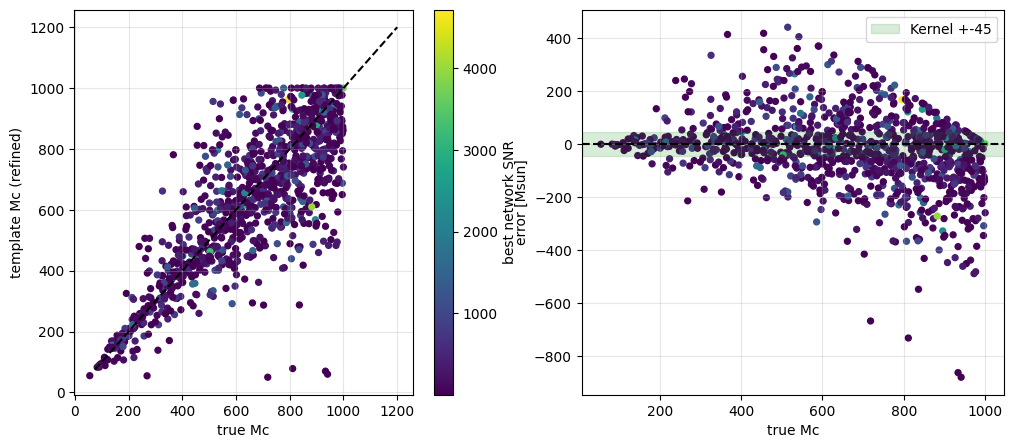

bin
0         [0.5, 0.5, 0.5]
1         [2.6, 6.3, 7.5]
2      [15.5, 35.7, 44.9]
3     [17.4, 93.9, 201.8]
4    [36.7, 177.3, 266.4]
5    [59.9, 241.0, 415.9]
6    [83.9, 222.4, 369.5]
7    [84.3, 282.8, 537.7]
Name: err_mc_refined, dtype: object


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sc = ax[0].scatter(res.chirp_mass_true, res.mc_refined, c=res.snr_best, s=18, cmap="viridis")
lim = [75, 1200]; ax[0].plot(lim, lim, "k--"); plt.colorbar(sc, ax=ax[0], label="best network SNR")
ax[0].set(xlabel="true Mc", ylabel="template Mc (refined)")
ax[1].scatter(res.chirp_mass_true, res.err_mc_refined, s=18, c=res.snr_best)
ax[1].axhspan(-45, 45, color="g", alpha=0.15, label="Kernel +-45")
ax[1].axhline(0, color="k", ls="--"); ax[1].set(xlabel="true Mc", ylabel="error [Msun]"); ax[1].legend()
for a in ax: a.grid(alpha=0.3)
plt.show()

# Fehlerquantile in Mc-Bins -> Grundlage fuer die Kernel-Breite
bins = np.geomspace(75, 1200, 8)
res["bin"] = np.digitize(res.chirp_mass_true, bins)
print(res.groupby("bin").err_mc_refined.agg(lambda x: np.quantile(np.abs(x), [0.5, 0.9, 0.99]).round(1).tolist()))